# One atom as the sample: which atom reacts

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/27_which_atom_reacts.ipynb)

Every notebook so far gave one number to a whole structure. Some questions belong to a single
atom instead: which nitrogen is protonated first, which carbon carries the chemical shift, which
position of a drug an enzyme attacks. The program answers these with the same fields, read
**around one atom**: the field of the molecule is weighted by an envelope centred on that atom,
and the rotation-invariant kernel of the second notebook compares two such environments.

The example here is the site of metabolism. A cytochrome P450 enzyme oxidises a drug molecule at
one or two of its twenty-odd heavy atoms, and a medicinal chemist who wants to slow that down
blocks the position. The data set is the published benchmark of Zaretzki, Matlock and Swamidass
(2013), in the form the FAME.AL project publishes (MIT licence), prepared in three dimensions and
kept in the repository: 636 molecules, 14,488 heavy atoms, 1,301 of them annotated as sites.

The measure is the one this field uses: in what share of the molecules is a true site among the
**two atoms the model ranks highest**. A chemist blocks one or two positions, so that is the
number that decides whether a model is useful.

The notebook asks three questions.

1. How is a target that belongs to an atom set up, and how are the folds drawn?
2. Does the field around an atom predict better than counting the atom types around it?
3. The references: a count over bonds, which needs no geometry at all, and a few properties of
   the atom itself, of the kind the published rule-based predictors score an atom with.

Running time: about two minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data: a target that belongs to an atom

`AtomTargets` holds one row per measured atom, with the molecule it belongs to and its index in
that molecule. The file marks each heavy atom with a property `som`, 1 for a site and 0
otherwise, so one molecule contributes as many rows as it has heavy atoms. The folds hold out
**whole molecules**, never single atoms: two atoms of the same molecule share almost all of their
surroundings, so splitting them would let the model see the answer.

The cell loads the set and draws three molecules with their annotated sites marked.

636 molecules, 14488 heavy atoms, 1301 of them sites (9.0 %)
the first molecule has 29 heavy atoms, so it gives 29 rows; its sites are atoms [15, 16]


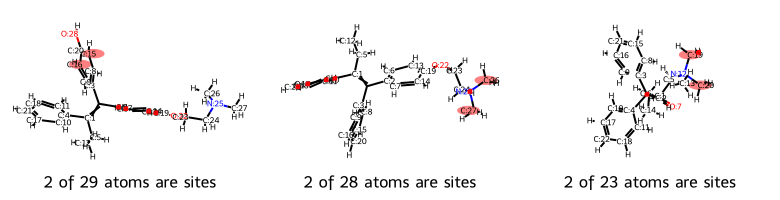

In [2]:
import json
import time

import numpy as np
from rdkit import RDLogger
from rdkit.Chem import Draw

RDLogger.DisableLog("rdApp.*")
sys.path.insert(0, "benchmarks")
import run_metabolism as RMB                       # the benchmark script of plan item MC8

start = time.time()
mols, fields, targets = RMB.read()                 # molecules, their fields, one row per heavy atom
print("%d molecules, %d heavy atoms, %d of them sites (%.1f %%)"
      % (targets.n_measured_molecules, len(targets), int(targets.y.sum()),
         100 * targets.y.mean()))
first = np.flatnonzero(targets.molecule == 0)
print("the first molecule has %d heavy atoms, so it gives %d rows; its sites are atoms %s"
      % (mols[0].GetNumHeavyAtoms(), len(first),
         targets.atom[first][targets.y[first] > 0].astype(int).tolist()))

sites = {i: [int(targets.atom[r]) for r in np.flatnonzero((targets.molecule == i) & (targets.y > 0))]
         for i in range(3)}
Draw.MolsToGridImage([mols[i] for i in sites], molsPerRow=3, subImgSize=(260, 200),
                     highlightAtomLists=[sites[i] for i in sites],
                     legends=["%d of %d atoms are sites" % (len(sites[i]), mols[i].GetNumHeavyAtoms())
                              for i in sites])

Nine per cent of the atoms are sites, and a molecule has 23 heavy atoms on average. So picking
two atoms at random would find a site in about 18 % of the molecules. Every model below is far
above that, because most of what any of them learns is which atom types are attacked at all.
What separates them is how much is left once that is known.

The three molecules show why the question is hard. The marked atoms are not the only ones of
their element, and in two of them several equivalent-looking carbons are not marked.

## Four descriptions of one atom

Each row below describes the same atom in a different way. All four are given to the same model
(ridge regression on the rows, the ridge chosen the same way for each), the same ten folds, and
the same measure.

- **count over bonds**: how many atoms of each type lie one, two, three and four bonds away. This
  is what a model with no geometry has, and it is the baseline the plan item names.
- **count over distance**: the same atom types counted in shells of distance instead of bonds. It
  needs the geometry but no field.
- **atom properties**: eight numbers about the atom itself, of the kind the published rule-based
  predictors use: its element, the hydrogens on it, whether it is aromatic or in a ring, how many
  heavy neighbours it has, and how far it sits from the middle of the molecule.
- **the local field**: the five fields of the molecule weighted by an envelope around the atom,
  compared through the distances between pairs of weighted atoms. The envelope width rho is set
  to 0.25, which the benchmark's search chose.

In [3]:
from cmfqsar.localenv import (LOCAL_SPEC, count_features, environments, local_features,
                              topological_features, types_of)
from cmfqsar.locallarge import normalised_rows

types = types_of(fields, min_atoms=10)             # the atom types that occur often enough
rows = {}
rows["count over bonds"] = normalised_rows(topological_features(mols, targets, types),
                                           scale=np.ones(1))[0]
counts = count_features(fields, targets, types)
rows["count over distance"] = normalised_rows(counts, scale=np.ones(counts.shape[1]))[0]
properties = RMB.atom_properties(mols, targets)
rows["atom properties"] = normalised_rows(properties - properties.min(axis=0),
                                          scale=np.ones(properties.shape[1]))[0]
field = normalised_rows(local_features(environments(fields, targets, rho=0.25)),
                        n_bins=LOCAL_SPEC.n_bins)[0]
rows["the local field"] = field
print("columns per description:", {k: v.shape[1] for k, v in rows.items()})
atom = mols[0].GetAtomWithIdx(int(targets.atom[0]))        # the first row's atom, as RDKit sees it
print("the first row's atom: %s, %d hydrogens, aromatic %s, in a ring %s, %d heavy neighbours"
      % (atom.GetSymbol(), atom.GetTotalNumHs(), atom.GetIsAromatic(), atom.IsInRing(),
         atom.GetDegree()))
print("the columns of that description:", ", ".join(RMB.PROPERTY_NAMES),
      "(and one column per hydrogen count)")

columns per description: {'count over bonds': 110, 'count over distance': 154, 'atom properties': 12, 'the local field': 255}
the first row's atom: C, 0 hydrogens, aromatic False, in a ring False, 3 heavy neighbours
the columns of that description: hydrogens on the atom, aromatic, in a ring, heavy-atom neighbours, relative span, carbon, nitrogen, sulphur (and one column per hydrogen count)


The four descriptions differ in width as well as in kind: 110, 154, 12 and 255 columns. Each is
normalised so that a row has unit length, which makes the inner product of two rows a kernel of
the same scale for all four.

The local field has the most columns and the least direct information: it is built from
distances between pairs of weighted atoms, so it never names the atom at its centre. The atom
properties name it directly and hold nothing about the surroundings. The counts lie between.

In [4]:
hits = {}
scored = {}
for name, Z in rows.items():
    row, h1, h2 = RMB.score(name, Z, targets, 10, 0)
    scored[name], hits[name] = row, h2
mixture = np.hstack([rows["count over distance"], rows["the local field"]]) / np.sqrt(2.0)
row, h1, h2 = RMB.score("count over distance and the local field", mixture, targets, 10, 0)
scored["count over distance and the local field"], hits["count over distance and the local field"] = row, h2

print()
print("%-38s %8s %8s   %s" % ("description", "top-1", "top-2", "top-2 against the count over bonds"))
for name, r in scored.items():
    d = RMB.paired(hits[name], hits["count over bonds"])
    cell = "--" if name == "count over bonds" else "%+.1f %% [%+.1f, %+.1f]" % (100 * d[0], 100 * d[1], 100 * d[2])
    print("%-38s %7.1f%% %7.1f%%   %s" % (name, 100 * r["top1"], 100 * r["top2"], cell))
d = RMB.paired(hits["count over distance and the local field"], hits["count over distance"])
print()
print("the mixture against the count over distance: %+.1f %% [%+.1f, %+.1f]"
      % (100 * d[0], 100 * d[1], 100 * d[2]))
print("two atoms taken at random would find a site in about %.0f %% of the molecules"
      % (200 * targets.y.mean()))
print("(%.0f s)" % (time.time() - start))

  count over bonds           top-1 53.6%  top-2 70.9%  area under the curve 0.859  (ridge 0.01, 2 s)


  count over distance        top-1 57.5%  top-2 73.9%  area under the curve 0.864  (ridge 0.01, 2 s)


  atom properties            top-1 37.6%  top-2 55.2%  area under the curve 0.775  (ridge 0.01, 0 s)


  the local field            top-1 55.0%  top-2 71.1%  area under the curve 0.853  (ridge 0.0001, 3 s)


  count over distance and the local field top-1 60.8%  top-2 76.9%  area under the curve 0.875  (ridge 0.01, 5 s)



description                               top-1    top-2   top-2 against the count over bonds
count over bonds                          53.6%    70.9%   --
count over distance                       57.5%    73.9%   +3.0 % [+0.3, +5.5]
atom properties                           37.6%    55.2%   -15.7 % [-19.2, -12.1]


the local field                           55.0%    71.1%   +0.2 % [-3.3, +3.8]
count over distance and the local field    60.8%    76.9%   +6.0 % [+3.3, +8.8]

the mixture against the count over distance: +3.0 % [+0.5, +5.7]
two atoms taken at random would find a site in about 18 % of the molecules
(41 s)


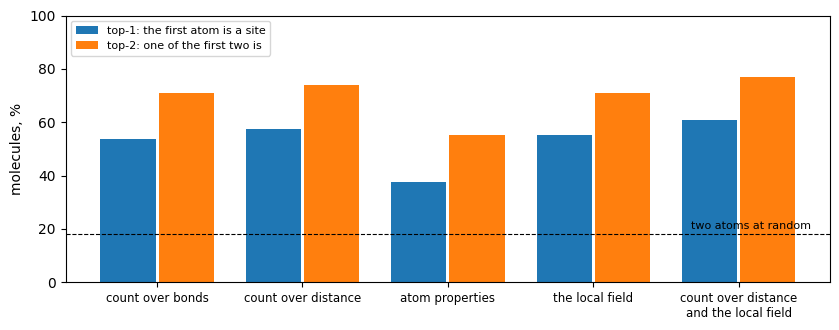

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.5, 3.4))
names_s = list(scored)
x = np.arange(len(names_s))
ax.bar(x - 0.2, [100 * scored[n]["top1"] for n in names_s], 0.38, label="top-1: the first atom is a site")
ax.bar(x + 0.2, [100 * scored[n]["top2"] for n in names_s], 0.38, label="top-2: one of the first two is")
ax.axhline(200 * targets.y.mean(), color="black", ls="--", lw=0.8)
ax.text(len(names_s) - 0.5, 200 * targets.y.mean() + 2, "two atoms at random", ha="right", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([n.replace("count over distance and the local field", "count over distance\nand the local field")
                    for n in names_s], fontsize=8.5)
ax.set_ylabel("molecules, %")
ax.set_ylim(0, 100)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**The field alone does not beat a count.** The local field reaches 71.1 %, and the count over
bonds, which needs no geometry at all, reaches 70.9 %. The interval of the difference contains
zero. Counting the same atom types over distance instead of over bonds is better than both:
73.9 %, ahead of the bond count by 3.0 % [0.3, 5.5].

**The atom's own properties are much weaker:** 55.2 %, far below every count. Knowing that an
atom is an aromatic carbon with one hydrogen, in a ring, near the edge of the molecule, does not
say which of the several such atoms the enzyme picks. The surroundings decide that.

**The field adds next to the count.** The two together reach 76.9 %, ahead of the count over
distance by 3.0 % [0.5, 5.7] and of the bond count by 6.0 % [3.3, 8.8]. That is what plan item
MC8 asked for. So the two descriptions hold different things: the count says which atom types
lie at which distance, the field says how charge and shape are arranged there, and neither
carries the other.

All five live numbers repeat the stored benchmark exactly, which the next cell checks.

In [6]:
with open("benchmarks/results/metabolism/summary.json", encoding="utf-8") as fh:
    stored = json.load(fh)
print("the stored benchmark, the same folds and measure")
print("%-44s %8s %8s %8s" % ("descriptor", "top-1", "top-2", "area under the curve"))
for r in stored["rows"]:
    print("%-44s %7.1f%% %7.1f%% %8.3f" % (r["name"], 100 * r["top1"], 100 * r["top2"], r["auc"]))
live = {"count over bonds": "count over bonds (2D)", "count over distance": "count over distance (3D)",
        "atom properties": "atom properties", "the local field": "local field, rho 0.25",
        "count over distance and the local field": "count and field, rho 0.25"}
same = all(abs(scored[k]["top2"] - next(r for r in stored["rows"] if r["name"] == v)["top2"]) < 1e-12
           for k, v in live.items())
print()
print("the live rows repeat the stored ones:", same)

the stored benchmark, the same folds and measure
descriptor                                      top-1    top-2 area under the curve
count over bonds (2D)                           53.6%    70.9%    0.859
count over distance (3D)                        57.5%    73.9%    0.864
atom properties                                 37.6%    55.2%    0.775
2D count and atom properties                    54.2%    70.9%    0.861
3D count and atom properties                    57.7%    74.4%    0.867
local field, rho 0.15                           54.4%    70.1%    0.843
local field, rho 0.25                           55.0%    71.1%    0.853
local field, rho 0.5                            55.2%    69.7%    0.854
local field, rho 1                              55.3%    69.3%    0.844
local field, rho 2                              53.0%    66.5%    0.837
count and field, rho 0.25                       60.8%    76.9%    0.875
count, field and atom properties, rho 0.25      61.3%    76.9%    0.878
cen

The stored rows include the local field at several envelope widths rho. The picture plots its
top-2 against rho, with the two counts as horizontal lines.

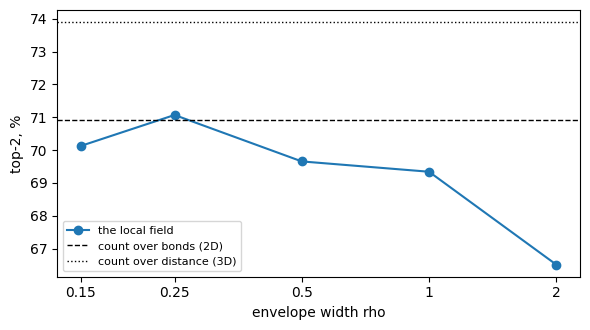

In [7]:
field_rows = sorted(((float(r["name"].split("rho")[1]), r["top2"]) for r in stored["rows"]
                     if r["name"].startswith("local field, rho")))
if field_rows:
    fig, ax = plt.subplots(figsize=(6, 3.4))
    ax.plot([f[0] for f in field_rows], [100 * f[1] for f in field_rows], "o-", label="the local field")
    for name, style in (("count over bonds (2D)", "--"), ("count over distance (3D)", ":")):
        r = next(r for r in stored["rows"] if r["name"] == name)
        ax.axhline(100 * r["top2"], color="black", ls=style, lw=1, label=name)
    ax.set_xscale("log")
    ax.set_xticks([f[0] for f in field_rows])
    ax.set_xticklabels(["%g" % f[0] for f in field_rows])
    ax.minorticks_off()
    ax.set_xlabel("envelope width rho")
    ax.set_ylabel("top-2, %")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("no stored rows of the local field at several widths")

The stored rows add three things.

- **The width was chosen, not taken from the edge of a range.** The field rows rise to rho 0.25
  and fall on both sides of it. A wide envelope makes every atom of a molecule look alike,
  because the features are then measured from the whole molecule and not from the centre; a
  narrow one leaves too little of the molecule inside the envelope to tell two carbons apart.
- **Most of what the count adds to the mixture is the name of the atom.** Replacing the whole
  count by its first block alone, the centre's own atom type, still reaches 74.8 % where the
  whole count reaches 76.9 %. The field starts without the one variable that matters most, the
  element being asked about, and has to recover it indirectly.
- **The atom properties do not replace the field.** Added to the count over distance they reach
  74.4 %, which is no better than the count with the field (the difference is -2.5 %
  [-5.5, +0.2]). Added to the mixture they change nothing: 76.9 %, +0.0 % [-1.3, +1.3]. So
  whatever those properties hold about an atom, the count and the field between them already
  hold it.

This is the one case in this series of notebooks where the cheap reference did **not** overturn
the field model. In the design loop, the herding pick, the DFT grids and the metal particles it
did.

## What to take from this notebook

- A target can belong to one atom. `AtomTargets` holds one row per atom, the field is read
  through an envelope around it, and the folds hold out whole molecules.
- On this set the field around an atom is no better than counting atom types over bonds, and
  worse than counting them over distance.
- It earns its place beside a count, not instead of one: the two together find a site among the
  top two atoms in 76.9 % of the molecules, against 73.9 % for the count alone.
- Give the count the geometry too before crediting the field with it. Counting the same types in
  shells of distance rather than bonds is worth 3.0 % on its own.
- A description built from distances between pairs of atoms never names its own centre. Where
  the element of the atom decides most of the answer, as it does here, that is a real handicap.

From the command line:

```
cmf local examples/local/metabolism.sdf --target som --rank --primal --reference
```

`--primal` fits in the space of the columns instead of the kernel, which matters here: 14,488
atoms would give a kernel of 1.7 GB, and the same model in the columns needs 10 MB.

`--reference` fits the count model on the same folds and bootstraps the difference, which is the
comparison this notebook makes by hand. The command runs one envelope width, 0.5 by default, and
its count is a slightly different one, so its numbers are near the table above and not equal to
it; it reaches 69.7 % against the count's 69.0 % and reports that the field is no better.

Where to read further in the manual: *An atom instead of a molecule: the local invariant kernel*
has the envelope, the local kernel and the per-atom folds; *Which atom is attacked: a site of
metabolism* has this benchmark with all of its rows.